# Assignment 2: Convolution: Cats vs. Dogs

**Research question:** How does the number of training images change whether a CNN trained from scratch or a frozen pretrained CNN (VGG16) performs better?

**Data:** Dog and Cat Classification Dataset (Kaggle, by Bhavik Jikadara): https://www.kaggle.com/datasets/bhavikjikadara/dog-and-cat-classification-dataset
The folder `PetImages` has `Cat` and `Dog` subfolders. The copy used in this run contains 12,499 JPEG images per class (24,998 total); see Section 2.

**How to run:**
1. Runtime → Change runtime type → Hardware accelerator: **GPU**.
2. Upload the dataset zip to the Colab Files panel (or set `ZIP_PATH` in Section 2 to its location).
3. Run the cells from top to bottom. Finished experiments are saved in `/content/results`, and any experiment whose result file already exists is skipped.

**Contents:** 1 Setup · 2 Data extraction · 3 Image readability check · 4 Train/validation/test splits · 5 Input pipeline and models · 6 Experiments 1–3 (from scratch) · 7 Experiments 4–6 (pretrained VGG16) · 8 Results · 9 Reproducibility and limitations

## 1. Setup

Import the libraries, fix the random seed, and create the working folders. The seed makes the image selection and the training repeatable as far as the GPU allows.

In [4]:
import os, glob, json, random, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from PIL import Image

warnings.filterwarnings("ignore", category=UserWarning)  # hides a harmless PIL warning about truncated TIFF files

SEED = 42
IMG_SIZE = 150                  # images are resized to 150 x 150 x 3
BATCH_SIZE = 32
EPOCHS = 30
TEST_PER_CLASS = 500
VAL_PER_CLASS = 500
LABEL_MAP = {"Cat": 0, "Dog": 1}  # Dog is the positive class of the sigmoid output

ZIP_PATH = "/content/archive (1).zip"   # where the uploaded dataset zip is stored
DATA_DIR = "/content/data"
MANIFEST_PATH = f"{DATA_DIR}/split_manifest.csv"
RESULTS_DIR = "/content/results"
CKPT_DIR = "/content/checkpoints"
for folder in [DATA_DIR, RESULTS_DIR, CKPT_DIR]:
    os.makedirs(folder, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__, "| GPUs visible:", len(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0 | GPUs visible: 1


## 2. Data extraction

Unzip the dataset into `/content/data` and count the images in each class. Colab's local disk is much faster for training than Google Drive, so the images are copied there.

In [5]:
if not os.path.exists(f"{DATA_DIR}/PetImages"):
    assert os.path.exists(ZIP_PATH), f"Zip not found at {ZIP_PATH}. Check the Files panel and update ZIP_PATH."
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall(DATA_DIR)

for label in ["Cat", "Dog"]:
    print(f"{label}: {len(glob.glob(f'{DATA_DIR}/PetImages/{label}/*.jpg'))} .jpg files")

Cat: 12499 .jpg files
Dog: 12499 .jpg files


## 3. Image readability check

A JPEG can have a valid header and still be cut off inside. This first check uses PIL's header verification, which is fast but does not decode the pixels. Section 4 adds a second check that uses TensorFlow's decoder, the same one used during training.

In [6]:
all_paths = sorted(glob.glob(f"{DATA_DIR}/PetImages/*/*.jpg"))

def pil_header_ok(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

pil_unreadable = {p for p in all_paths if not pil_header_ok(p)}
print("Images checked:", len(all_paths))
print("PIL header failures:", [os.path.basename(p) for p in sorted(pil_unreadable)])

Images checked: 24998
PIL header failures: []


## 4. Train, validation, and test splits

- **Test set:** 500 cats + 500 dogs. Used only for the final evaluation of each experiment.
- **Validation set:** 500 cats + 500 dogs. Used for early stopping and learning-rate reduction, never for gradient updates.
- **Training pool:** all remaining images, shuffled with a fixed seed. Each experiment uses the first N images per class, so the smaller training sets are contained in the larger ones.

Images that TensorFlow cannot decode are removed from the training pool only. If one appears in the validation or test set, the cell stops with an error.

In [7]:
# Assign files to test, validation, and training pool, with the same seeded shuffle for every run
rng = random.Random(SEED)
rows = []
for label in ["Cat", "Dog"]:
    files = sorted(p for p in glob.glob(f"{DATA_DIR}/PetImages/{label}/*.jpg") if p not in pil_unreadable)
    rng.shuffle(files)
    rows += [(p, label, "test") for p in files[:TEST_PER_CLASS]]
    rows += [(p, label, "validation") for p in files[TEST_PER_CLASS:TEST_PER_CLASS + VAL_PER_CLASS]]
    rows += [(p, label, "train_pool") for p in files[TEST_PER_CLASS + VAL_PER_CLASS:]]
manifest = pd.DataFrame(rows, columns=["path", "label", "split"])

# Decode every image with TensorFlow's decoder, the same one used in training
def tf_decodes(path):
    try:
        tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        return True
    except Exception:
        return False

manifest["decodes"] = manifest["path"].apply(tf_decodes)
failed = manifest[~manifest["decodes"]]
print("Images TensorFlow cannot decode:", len(failed))
print(failed[["path", "split", "label"]].to_string(index=False))
assert (failed["split"] == "train_pool").all(), "An unreadable image is in validation or test. Stop and review."

# Remove the unreadable training images and rank the rest within each class (order is already shuffled)
manifest = manifest[manifest["decodes"]].drop(columns="decodes").reset_index(drop=True)
manifest["pool_rank"] = -1
in_pool = manifest["split"] == "train_pool"
for label in ["Cat", "Dog"]:
    idx = manifest[in_pool & (manifest["label"] == label)].index
    manifest.loc[idx, "pool_rank"] = range(len(idx))

# Safety checks: no duplicate files, and fixed validation and test sizes
assert manifest["path"].is_unique, "A file appears in more than one split"
assert (manifest[manifest["split"] == "test"].groupby("label").size() == TEST_PER_CLASS).all()
assert (manifest[manifest["split"] == "validation"].groupby("label").size() == VAL_PER_CLASS).all()

manifest.to_csv(MANIFEST_PATH, index=False)
print(manifest.groupby(["split", "label"]).size())

Images TensorFlow cannot decode: 7
                                 path      split label
/content/data/PetImages/Cat/10404.jpg train_pool   Cat
 /content/data/PetImages/Cat/4351.jpg train_pool   Cat
 /content/data/PetImages/Dog/2494.jpg train_pool   Dog
 /content/data/PetImages/Dog/2317.jpg train_pool   Dog
/content/data/PetImages/Dog/11912.jpg train_pool   Dog
 /content/data/PetImages/Dog/9500.jpg train_pool   Dog
/content/data/PetImages/Dog/11233.jpg train_pool   Dog
split       label
test        Cat        500
            Dog        500
train_pool  Cat      11497
            Dog      11494
validation  Cat        500
            Dog        500
dtype: int64


## 5. Input pipeline and models

Two input pipelines are used, one for each model type:
- **From scratch:** pixels are scaled to 0–1 inside the model (`Rescaling(1/255)`).
- **Pretrained VGG16:** scaling is done using VGG16's own preprocess_input, since this is the scaling the ImageNet weights are expecting. The weights would not be suitable for plain 0–1 scaling.

**From-scratch CNN:** The model consists of four conv2D+max pooling blocks with filters of 32, 64, 128 and 128, followed by a Dropout of 0.5, then a 512 unit dense layer, and then one sigmoid output. The augmentation functions (flip, rotation, zoom) are only executed while training.

**Pretrained CNN:** VGG16 with ImageNet weights, with the convolutional base **frozen** (its weights are not updated). A small new head of 256 units and one sigmoid output is trained on top.

In [8]:
def identity(x):
    return x

def load_image(path, label, preprocess):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    return preprocess(image), label

def make_dataset(frame, preprocess, shuffle=False):
    labels = frame["label"].map(LABEL_MAP).values.astype("float32")
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].values, labels))
    if shuffle:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda path, label: load_image(path, label, preprocess), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def compile_model(model):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

def augmentation_layers():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ], name="augmentation")

def build_scratch_cnn():
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augmentation_layers()(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for filters in [32, 64, 128, 128]:
        x = layers.Conv2D(filters, (3, 3), activation="relu")(x)
        x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(512, activation="relu")(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return compile_model(keras.Model(inputs, outputs))

def build_vgg_model():
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    conv_base = VGG16(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    conv_base.trainable = False  # frozen: the ImageNet features are kept unchanged
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augmentation_layers()(inputs)
    x = conv_base(x, training=False)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation="relu")(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return compile_model(keras.Model(inputs, outputs))

def run_experiment(exp_id, approach, build_model, preprocess, preprocessing_note, images_per_class):
    """Train one experiment, evaluate once on the test set, and save its result."""
    result_path = f"{RESULTS_DIR}/exp{exp_id}.json"
    if os.path.exists(result_path):  # skip finished runs after a runtime restart
        with open(result_path) as f:
            return json.load(f)

    train_frame = manifest[(manifest["split"] == "train_pool") & (manifest["pool_rank"] < images_per_class)]
    val_frame = manifest[manifest["split"] == "validation"]
    test_frame = manifest[manifest["split"] == "test"]
    assert train_frame["label"].value_counts().nunique() == 1, "Training set is not balanced"

    model = build_model()
    callbacks = [
        keras.callbacks.ModelCheckpoint(f"{CKPT_DIR}/exp{exp_id}.keras", monitor="val_loss", save_best_only=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
    ]
    start = time.time()
    history = model.fit(make_dataset(train_frame, preprocess, shuffle=True),
                        validation_data=make_dataset(val_frame, preprocess),
                        epochs=EPOCHS, callbacks=callbacks, verbose=2)
    minutes = (time.time() - start) / 60

    test_loss, test_accuracy = model.evaluate(make_dataset(test_frame, preprocess), verbose=0)
    result = {
        "experiment": exp_id,
        "approach": approach,
        "train_images": len(train_frame),
        "validation_images": len(val_frame),
        "test_images": len(test_frame),
        "preprocessing": preprocessing_note,
        "optimizer": "Adam, learning rate 1e-4, ReduceLROnPlateau, early stopping (patience 5)",
        "epochs_run": len(history.history["loss"]),
        "best_val_loss": float(min(history.history["val_loss"])),
        "best_val_accuracy": float(max(history.history["val_accuracy"])),
        "test_accuracy": float(test_accuracy),
        "test_loss": float(test_loss),
        "training_minutes": round(minutes, 1),
        "seed": SEED,
    }
    with open(result_path, "w") as f:
        json.dump(result, f, indent=2)
    pd.DataFrame(history.history).to_csv(f"{RESULTS_DIR}/exp{exp_id}_history.csv", index=False)
    print(f"Experiment {exp_id}: {result['train_images']} training images | "
          f"test accuracy {test_accuracy:.4f} | test loss {test_loss:.4f} | {minutes:.1f} min")
    return result

## 6. Experiments 1–3: CNN trained from scratch

| Experiment | Training images (cats + dogs) | Why this size |
|---|---|---|
| 1 | 1,000 (500 + 500) | Required by the assignment |
| 2 | 2,000 (1,000 + 1,000) | Total stated in the professor's clarification |
| 3 | 5,000 (2,500 + 2,500) | A larger size. Chosen after Experiment 2 was run, which should be stated in the report |

Validation (1,000) and test (1,000) sets are the same in every experiment.

### Experiment 1: 1,000 training images

In [9]:
exp1 = run_experiment(1, "CNN from scratch", build_scratch_cnn, identity,
                      "Rescaling to 0–1 inside the model", images_per_class=500)

Epoch 1/30
32/32 - 10s - 297ms/step - accuracy: 0.5010 - loss: 0.6966 - val_accuracy: 0.5180 - val_loss: 0.6883 - learning_rate: 1.0000e-04
Epoch 2/30
32/32 - 5s - 164ms/step - accuracy: 0.5220 - loss: 0.6915 - val_accuracy: 0.5010 - val_loss: 0.6852 - learning_rate: 1.0000e-04
Epoch 3/30
32/32 - 2s - 73ms/step - accuracy: 0.5640 - loss: 0.6821 - val_accuracy: 0.5770 - val_loss: 0.6698 - learning_rate: 1.0000e-04
Epoch 4/30
32/32 - 2s - 73ms/step - accuracy: 0.5870 - loss: 0.6670 - val_accuracy: 0.5520 - val_loss: 0.6814 - learning_rate: 1.0000e-04
Epoch 5/30
32/32 - 2s - 64ms/step - accuracy: 0.5800 - loss: 0.6728 - val_accuracy: 0.5480 - val_loss: 0.6830 - learning_rate: 1.0000e-04
Epoch 6/30
32/32 - 2s - 68ms/step - accuracy: 0.6160 - loss: 0.6490 - val_accuracy: 0.6180 - val_loss: 0.6435 - learning_rate: 5.0000e-05
Epoch 7/30
32/32 - 2s - 74ms/step - accuracy: 0.6390 - loss: 0.6343 - val_accuracy: 0.6140 - val_loss: 0.6479 - learning_rate: 5.0000e-05
Epoch 8/30
32/32 - 2s - 70ms/st

### Experiment 2: 2,000 training images

In [10]:
exp2 = run_experiment(2, "CNN from scratch", build_scratch_cnn, identity,
                      "Rescaling to 0–1 inside the model", images_per_class=1000)

Epoch 1/30
63/63 - 6s - 92ms/step - accuracy: 0.5235 - loss: 0.6924 - val_accuracy: 0.6010 - val_loss: 0.6849 - learning_rate: 1.0000e-04
Epoch 2/30
63/63 - 3s - 52ms/step - accuracy: 0.5700 - loss: 0.6801 - val_accuracy: 0.5980 - val_loss: 0.6682 - learning_rate: 1.0000e-04
Epoch 3/30
63/63 - 5s - 86ms/step - accuracy: 0.5990 - loss: 0.6653 - val_accuracy: 0.6450 - val_loss: 0.6438 - learning_rate: 1.0000e-04
Epoch 4/30
63/63 - 4s - 57ms/step - accuracy: 0.6080 - loss: 0.6569 - val_accuracy: 0.6440 - val_loss: 0.6361 - learning_rate: 1.0000e-04
Epoch 5/30
63/63 - 5s - 75ms/step - accuracy: 0.6440 - loss: 0.6264 - val_accuracy: 0.6290 - val_loss: 0.6342 - learning_rate: 1.0000e-04
Epoch 6/30
63/63 - 4s - 56ms/step - accuracy: 0.6795 - loss: 0.6032 - val_accuracy: 0.6900 - val_loss: 0.5995 - learning_rate: 1.0000e-04
Epoch 7/30
63/63 - 4s - 59ms/step - accuracy: 0.6855 - loss: 0.5981 - val_accuracy: 0.6780 - val_loss: 0.5933 - learning_rate: 1.0000e-04
Epoch 8/30
63/63 - 3s - 51ms/step 

### Experiment 3: 5,000 training images

In [11]:
exp3 = run_experiment(3, "CNN from scratch", build_scratch_cnn, identity,
                      "Rescaling to 0–1 inside the model", images_per_class=2500)

Epoch 1/30
157/157 - 9s - 54ms/step - accuracy: 0.5352 - loss: 0.6896 - val_accuracy: 0.6260 - val_loss: 0.6601 - learning_rate: 1.0000e-04
Epoch 2/30
157/157 - 7s - 42ms/step - accuracy: 0.6148 - loss: 0.6567 - val_accuracy: 0.6730 - val_loss: 0.6066 - learning_rate: 1.0000e-04
Epoch 3/30
157/157 - 6s - 40ms/step - accuracy: 0.6754 - loss: 0.6056 - val_accuracy: 0.7000 - val_loss: 0.5657 - learning_rate: 1.0000e-04
Epoch 4/30
157/157 - 6s - 41ms/step - accuracy: 0.7014 - loss: 0.5802 - val_accuracy: 0.6900 - val_loss: 0.5766 - learning_rate: 1.0000e-04
Epoch 5/30
157/157 - 10s - 64ms/step - accuracy: 0.7074 - loss: 0.5726 - val_accuracy: 0.7370 - val_loss: 0.5398 - learning_rate: 1.0000e-04
Epoch 6/30
157/157 - 6s - 40ms/step - accuracy: 0.7244 - loss: 0.5504 - val_accuracy: 0.7260 - val_loss: 0.5347 - learning_rate: 1.0000e-04
Epoch 7/30
157/157 - 10s - 65ms/step - accuracy: 0.7408 - loss: 0.5302 - val_accuracy: 0.7720 - val_loss: 0.4922 - learning_rate: 1.0000e-04
Epoch 8/30
157/157

## 7. Experiments 4–6: pretrained VGG16 (frozen base)

Experiment 4 uses the same training size as Experiment 1, Experiment 5 the same as Experiment 2, and Experiment 6 the same as Experiment 3. This keeps the two model types directly comparable.

### Experiment 4: 1,000 training images

In [12]:
exp4 = run_experiment(4, "Pretrained VGG16 (frozen base)", build_vgg_model, vgg_preprocess,
                      "VGG16 preprocess_input", images_per_class=500)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/30
32/32 - 8s - 259ms/step - accuracy: 0.7890 - loss: 3.0886 - val_accuracy: 0.9400 - val_loss: 0.6541 - learning_rate: 1.0000e-04
Epoch 2/30
32/32 - 9s - 281ms/step - accuracy: 0.8990 - loss: 1.2631 - val_accuracy: 0.9550 - val_loss: 0.4591 - learning_rate: 1.0000e-04
Epoch 3/30
32/32 - 6s - 173ms/step - accuracy: 0.9260 - loss: 0.9302 - val_accuracy: 0.9570 - val_loss: 0.4318 - learning_rate: 1.0000e-04
Epoch 4/30
32/32 - 5s - 164ms/step - accuracy: 0.9350 - loss: 0.7193 - val_accuracy: 0.9580 - val_loss: 0.4413 - learning_rate: 1.0000e-04
Epoch 5/30
32/32 - 5s - 166ms/step - accuracy: 0.9430 - loss: 0.6558 - val_accuracy: 0.9600 - val_loss: 0.4502 - learning_rate: 1.0000e-04
Epoch 6/30
32/32 - 6s - 178ms/step - accuracy: 0.9470 - loss: 0.5601 - val_accuracy: 0.9670 - val_loss: 0.3395 - learning_rate: 5.0000e-05
Epoch 7/30
32/32 - 5s - 164ms/step - accuracy: 0.9530 - loss: 0.4273 - val_accuracy: 0.9670 - val_loss: 0.3505 - le

### Experiment 5: 2,000 training images

In [13]:
exp5 = run_experiment(5, "Pretrained VGG16 (frozen base)", build_vgg_model, vgg_preprocess,
                      "VGG16 preprocess_input", images_per_class=1000)

Epoch 1/30
63/63 - 10s - 151ms/step - accuracy: 0.8345 - loss: 2.4125 - val_accuracy: 0.9570 - val_loss: 0.3932 - learning_rate: 1.0000e-04
Epoch 2/30
63/63 - 7s - 117ms/step - accuracy: 0.9180 - loss: 0.9593 - val_accuracy: 0.9580 - val_loss: 0.4463 - learning_rate: 1.0000e-04
Epoch 3/30
63/63 - 11s - 173ms/step - accuracy: 0.9285 - loss: 0.9028 - val_accuracy: 0.9620 - val_loss: 0.3359 - learning_rate: 1.0000e-04
Epoch 4/30
63/63 - 8s - 130ms/step - accuracy: 0.9340 - loss: 0.7536 - val_accuracy: 0.9660 - val_loss: 0.3276 - learning_rate: 1.0000e-04
Epoch 5/30
63/63 - 8s - 132ms/step - accuracy: 0.9360 - loss: 0.6806 - val_accuracy: 0.9670 - val_loss: 0.2744 - learning_rate: 1.0000e-04
Epoch 6/30
63/63 - 8s - 122ms/step - accuracy: 0.9475 - loss: 0.5356 - val_accuracy: 0.9680 - val_loss: 0.2943 - learning_rate: 1.0000e-04
Epoch 7/30
63/63 - 8s - 122ms/step - accuracy: 0.9435 - loss: 0.5693 - val_accuracy: 0.9700 - val_loss: 0.3053 - learning_rate: 1.0000e-04
Epoch 8/30
63/63 - 10s - 

### Experiment 6: 5,000 training images

In [14]:
exp6 = run_experiment(6, "Pretrained VGG16 (frozen base)", build_vgg_model, vgg_preprocess,
                      "VGG16 preprocess_input", images_per_class=2500)

Epoch 1/30
157/157 - 17s - 107ms/step - accuracy: 0.8834 - loss: 1.4317 - val_accuracy: 0.9670 - val_loss: 0.3672 - learning_rate: 1.0000e-04
Epoch 2/30
157/157 - 16s - 103ms/step - accuracy: 0.9276 - loss: 0.9029 - val_accuracy: 0.9680 - val_loss: 0.2923 - learning_rate: 1.0000e-04
Epoch 3/30
157/157 - 20s - 126ms/step - accuracy: 0.9300 - loss: 0.8198 - val_accuracy: 0.9700 - val_loss: 0.2357 - learning_rate: 1.0000e-04
Epoch 4/30
157/157 - 15s - 95ms/step - accuracy: 0.9372 - loss: 0.6077 - val_accuracy: 0.9740 - val_loss: 0.1911 - learning_rate: 1.0000e-04
Epoch 5/30
157/157 - 15s - 94ms/step - accuracy: 0.9452 - loss: 0.4219 - val_accuracy: 0.9700 - val_loss: 0.1790 - learning_rate: 1.0000e-04
Epoch 6/30
157/157 - 15s - 96ms/step - accuracy: 0.9438 - loss: 0.4370 - val_accuracy: 0.9670 - val_loss: 0.1583 - learning_rate: 1.0000e-04
Epoch 7/30
157/157 - 15s - 98ms/step - accuracy: 0.9490 - loss: 0.3662 - val_accuracy: 0.9730 - val_loss: 0.1335 - learning_rate: 1.0000e-04
Epoch 8/30

## 8. Results

The table is built from the saved result files, so it contains only experiments that finished. The figure shows test accuracy against training-set size. Test accuracy is measured on 1,000 images, so differences of about 2 percentage points or less should not be over-interpreted.

In [15]:
summary_rows = []
for path in sorted(glob.glob(f"{RESULTS_DIR}/exp*.json")):
    with open(path) as f:
        summary_rows.append(json.load(f))
summary = pd.DataFrame(summary_rows).sort_values("experiment").reset_index(drop=True)
summary.to_csv(f"{RESULTS_DIR}/results_summary.csv", index=False)

display_cols = ["experiment", "approach", "train_images", "validation_images", "test_images",
                "test_accuracy", "test_loss", "training_minutes"]
print(summary[display_cols].to_string(index=False, float_format="%.4f"))

 experiment                       approach  train_images  validation_images  test_images  test_accuracy  test_loss  training_minutes
          1               CNN from scratch          1000               1000         1000         0.6030     0.6382            0.7000
          2               CNN from scratch          2000               1000         1000         0.7610     0.5064            2.2000
          3               CNN from scratch          5000               1000         1000         0.8240     0.3849            4.0000
          4 Pretrained VGG16 (frozen base)          1000               1000         1000         0.9530     0.6006            1.1000
          5 Pretrained VGG16 (frozen base)          2000               1000         1000         0.9690     0.3984            2.4000
          6 Pretrained VGG16 (frozen base)          5000               1000         1000         0.9680     0.1270            5.3000


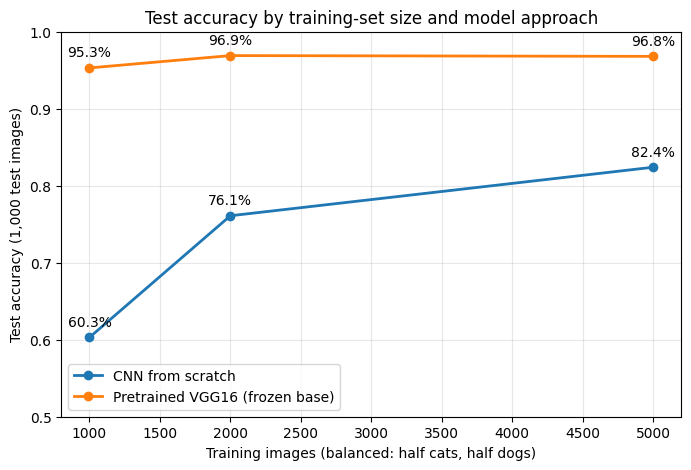

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
for approach, group in summary.groupby("approach"):
    ax.plot(group["train_images"], group["test_accuracy"], marker="o", linewidth=2, label=approach)
    for _, row in group.iterrows():
        ax.annotate(f"{row['test_accuracy']:.1%}", (row["train_images"], row["test_accuracy"]),
                    textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_xlabel("Training images (balanced: half cats, half dogs)")
ax.set_ylabel("Test accuracy (1,000 test images)")
ax.set_title("Test accuracy by training-set size and model approach")
ax.set_ylim(0.5, 1.0)
ax.grid(alpha=0.3)
ax.legend()
fig.savefig(f"{RESULTS_DIR}/results_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Results (all six experiments, from this run)

| Experiment | Approach | Training images | Test accuracy | Test loss | Epochs run |
|---|---|---:|---:|---:|---:|
| 1 | CNN from scratch | 1,000 | 60.30% | 0.6382 | 13 (early stop) |
| 2 | CNN from scratch | 2,000 | 76.10% | 0.5064 | 30 (full) |
| 3 | CNN from scratch | 5,000 | 82.40% | 0.3849 | 30 (full) |
| 4 | Pretrained VGG16 (frozen) | 1,000 | 95.30% | 0.6006 | 11 (early stop) |
| 5 | Pretrained VGG16 (frozen) | 2,000 | 96.90% | 0.3984 | 17 (early stop) |
| 6 | Pretrained VGG16 (frozen) | 5,000 | 96.80% | 0.1270 | 19 (early stop) |

Every run uses the same validation set (500 cats and 500 dogs) and the same test set (500 cats and 500 dogs). These values are copied from the `results_summary.csv` output in Section 8.

### Interpretation

**Training-set size and the from-scratch CNN.**
Test accuracy rose from 60.3% (1,000 images) to 76.1% (2,000) to 82.4% (5,000). Increasing the data by 100% increased the percentage by 15.8 points and increasing the data by 250% increased the percentage by 6.3 points. Both gains exceed the uncertainty in the test-set (around ±1.3 points at 80% accuracy), thus they are real for this experiment, but are getting smaller. The models which were not clearly converged were the loss in validation and it remained the lowest during the last epoch in Experiments 2 and 3.

**Training-set size and the pretrained model.**
Accuracy was already 95.3% at 1,000 images, rose to 96.9% at 2,000, and was 96.8% at 5,000. The difference between the 2,000 images and 5,000 images is one image out of 1,000 test images, so the accuracy had settled out. Test loss continued to decrease (0.601, 0.398, 0.127): Despite remaining the same, the model became more confident of its accurate predictions with more data.

**Relationship between sample size and model choice.**
The from-scratch model was outperformed by the pretrained model at all training sizes used. The gap narrowed as the scratch model received more data: 35.0 points at 1,000 images, 20.8 points at 2,000, and 14.4 points at 5,000. The pretrained model trained on 1,000 images achieved a performance of 95.3% while the scratch model trained on 5,000 images achieved 82.4%. The ImageNet features are most helpful with small data sets. The scratch model has not caught up at the largest size tested and this experiment does not indicate where the two curves would intersect.

**Best tested configuration.**
Experiment 5 (2,000 pretrained images, 96.9%) is the most accurate and Experiment 6 (5,000 pretrained images, 96.8%) is close. The Experiment 6 is the best (0.127) by test loss (compared with 0.398 for Experiment 5). Experiment 5 achieves almost the same accuracy with fewer training data, and Experiment 6 achieves the most confident correct predictions. There is no one-size-fits-all answer to this question.

**Test loss compared with validation loss.**
Test loss was also higher than the minimum Loss found in the validation data for each of the pre-trained runs (e.g. for 1,000 images, test loss was 0.601 while the best validation loss was 0.340). Early stopping restores the epoch with the lowest validation loss, which results in optimistically biased validation loss; and some of this difference is to be expected. The errors from the class where the model is confident would be reflected on a confusion matrix.

## 9. Reproducibility and limitations

- **Data copy used:** No header failures have been detected in this run, 24,998 JPEG images were extracted, 12,499 of which are contained in this run's extracted data. The previous run had 12,500 per class with 2 hits of header failures (Cat/666.jpg and Dog/11702.jpg). The two runs of the experiment are not identical and so the results of the earlier run (e.g. 69.8% for Experiment 1) are not included in this report.

- **Unreadable images:** There were no header failures in this run in Section 3. Section 4 found 7 images that TensorFlow cannot decode (`Cat/10404.jpg`, `Cat/4351.jpg`, `Dog/2494.jpg`, `Dog/2317.jpg`, `Dog/11912.jpg`, `Dog/9500.jpg`, `Dog/11233.jpg`). Everyone is training and they have all been taken off of the training pool. There is no change to the validation and test sets.

- **Fixed design:** the same seed, the same validation sets, and the same test sets (500 samples for each class), and a shared training pool. The split is stored in the file split_manifest.csv, while each result file contains the number of samples, preprocessing, and training time for each split.
Single run per experiment: One seed was used for each experiment. GPU training can take place slightly differently, so reruns aren't exactly repeatable bit for bit.

- **Test-set uncertainty:** with 1,000 test images, the standard error is about ±1.3 points at 80% accuracy, ±0.7 points at 95%, and ±0.5 points at 97%. If there is only a difference of 2-3 points or less, then it is not considered a real difference until repeated runs have been performed.

- **Scope:** A single dataset, one set of frozen VGG16 parameters (not tested for fine tuning), one scratch CNN design and training sizes of 1k to 5k images. The outcome is not meant to be applicable to beyond this setup.

- **Hyperparameters:** all six runs are the same. Early stopping and learning-rate reduction is based on validation loss only. The test set was only used for the last evaluation per experiment.